In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from pydicom.data import get_testdata_file

# Fichier de test fourni avec pydicom (scanner CT anonymisé)
chemin = get_testdata_file("CT_small.dcm")
ds = pydicom.dcmread(chemin)          # ds = "dataset" : en-tête + pixels

champs = [
    ("Modality", "Type d'examen"),
    ("Manufacturer", "Fabricant de l'appareil"),
    ("Rows", "Hauteur (pixels)"),
    ("Columns", "Largeur (pixels)"),
    ("PixelSpacing", "Taille d'un pixel (mm)"),
    ("SliceThickness", "Épaisseur de coupe (mm)"),
    ("BitsAllocated", "Bits par pixel"),
    ("RescaleSlope", "Rescale Slope"),
    ("RescaleIntercept", "Rescale Intercept"),
    ("WindowCenter", "Centre de fenêtre conseillé"),
    ("WindowWidth", "Largeur de fenêtre conseillée"),
]

for tag, description in champs:
    print(f"{description:32} : {getattr(ds, tag, 'absent')}")

Type d'examen                    : CT
Fabricant de l'appareil          : GE MEDICAL SYSTEMS
Hauteur (pixels)                 : 128
Largeur (pixels)                 : 128
Taille d'un pixel (mm)           : [0.661468, 0.661468]
Épaisseur de coupe (mm)          : 5.000000
Bits par pixel                   : 16
Rescale Slope                    : 1
Rescale Intercept                : -1024
Centre de fenêtre conseillé      : absent
Largeur de fenêtre conseillée    : absent


Brut  -> type : int16 | forme : (128, 128) | min : 128 | max : 2191
HU    -> min : -896.0 | max : 1167.0
Taille réelle : 84.7 mm x 84.7 mm


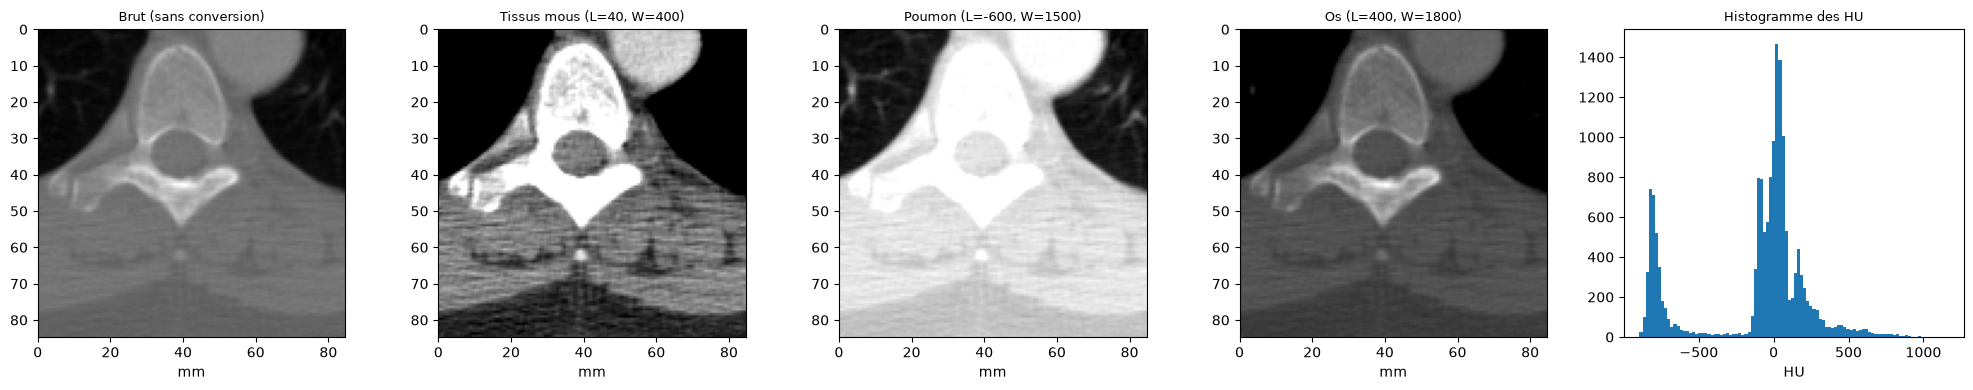

In [2]:
# 1. Les pixels bruts
brut = ds.pixel_array
print("Brut  -> type :", brut.dtype, "| forme :", brut.shape, "| min :", brut.min(), "| max :", brut.max())

# 2. Conversion en unités Hounsfield
hu = brut.astype(np.float32) * float(ds.RescaleSlope) + float(ds.RescaleIntercept)
print("HU    -> min :", hu.min(), "| max :", hu.max())

# 3. Taille réelle, pour afficher des axes en mm
dy, dx = (float(v) for v in ds.PixelSpacing)
hauteur_mm, largeur_mm = ds.Rows * dy, ds.Columns * dx
print(f"Taille réelle : {largeur_mm:.1f} mm x {hauteur_mm:.1f} mm")

# 4. Même fonction de fenêtrage qu'en S1
def fenetrage(img, centre, largeur):
    bas, haut = centre - largeur / 2, centre + largeur / 2
    img = np.clip(img, bas, haut)
    return ((img - bas) / (haut - bas) * 255).astype(np.uint8)

vues = {
    "Brut (sans conversion)": brut,
    "Tissus mous (L=40, W=400)": fenetrage(hu, 40, 400),
    "Poumon (L=-600, W=1500)": fenetrage(hu, -600, 1500),
    "Os (L=400, W=1800)": fenetrage(hu, 400, 1800),
}

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (titre, im) in zip(axes, vues.items()):
    ax.imshow(im, cmap="gray", extent=[0, largeur_mm, hauteur_mm, 0])   # axes en mm
    ax.set_title(titre, fontsize=9); ax.set_xlabel("mm")

# 5. Histogramme : la répartition des valeurs en HU
axes[4].hist(hu.ravel(), bins=100)
axes[4].set_title("Histogramme des HU", fontsize=9); axes[4].set_xlabel("HU")
plt.tight_layout(); plt.show()

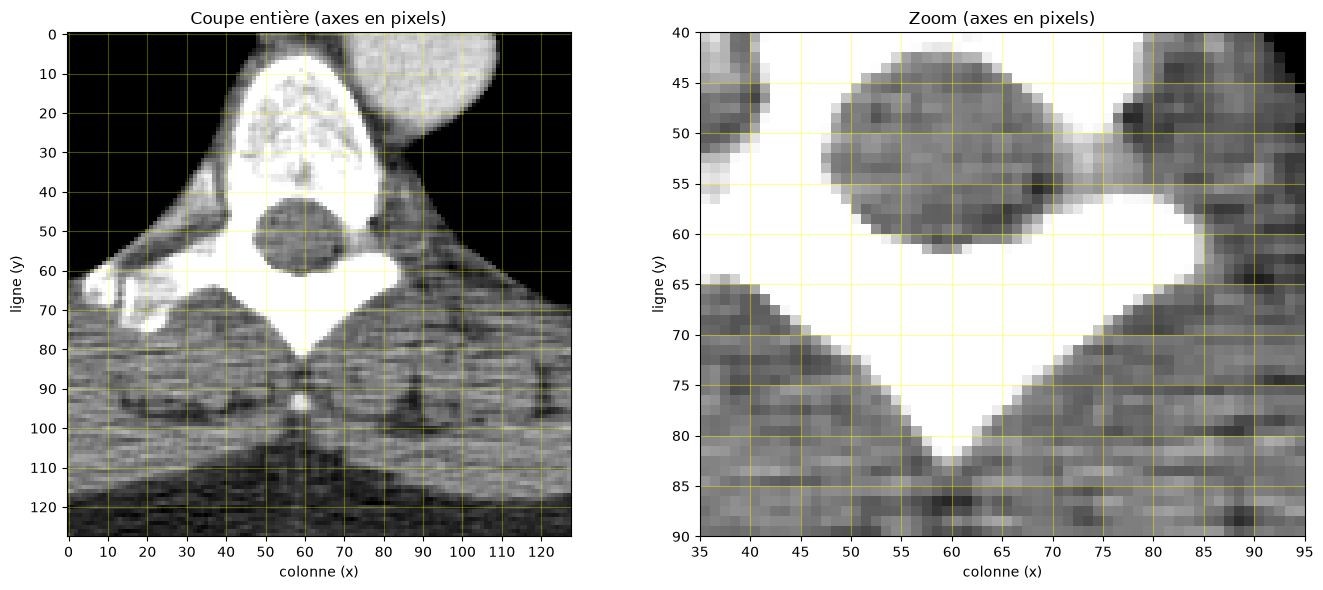

In [3]:
img_mous = fenetrage(hu, 40, 400)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Image entière, axes en pixels
axes[0].imshow(img_mous, cmap="gray")
axes[0].set_xticks(range(0, 128, 10)); axes[0].set_yticks(range(0, 128, 10))
axes[0].grid(color="yellow", alpha=0.3)
axes[0].set_title("Coupe entière (axes en pixels)")
axes[0].set_xlabel("colonne (x)"); axes[0].set_ylabel("ligne (y)")

# Zoom sur la zone centrale, où se trouve le canal
y1, y2, x1, x2 = 40, 90, 35, 95
axes[1].imshow(img_mous[y1:y2, x1:x2], cmap="gray", extent=[x1, x2, y2, y1])
axes[1].set_xticks(range(x1, x2 + 1, 5)); axes[1].set_yticks(range(y1, y2 + 1, 5))
axes[1].grid(color="yellow", alpha=0.4)
axes[1].set_title("Zoom (axes en pixels)")
axes[1].set_xlabel("colonne (x)"); axes[1].set_ylabel("ligne (y)")

plt.tight_layout(); plt.show()

Bords détectés : x = 47 et x = 71
Diamètre auto  : 23 px = 15.2 mm
Diamètre œil   : 20 px = 13.2 mm


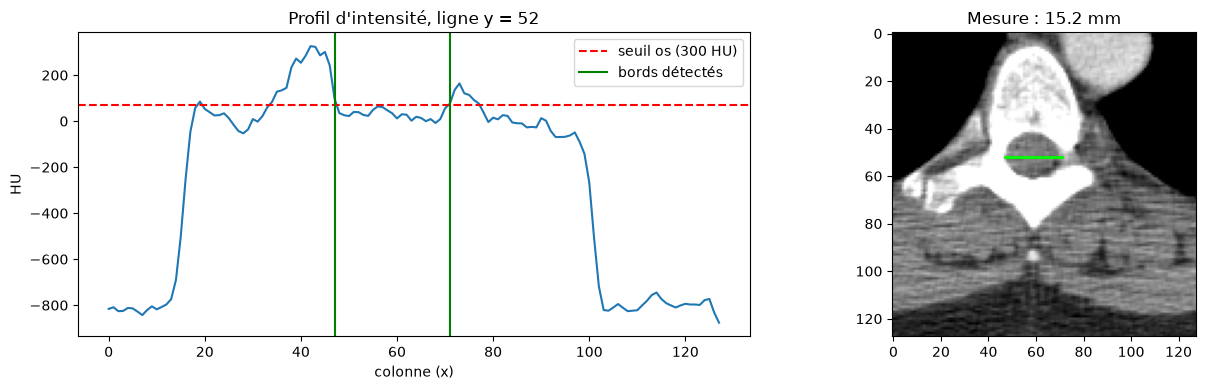

In [9]:
y = 52                        # ligne du centre du canal
x_gauche, x_droite = 50, 70   # ⚠️ remplace par TES deux valeurs lues sur le zoom
seuil_os = 70             # au-delà : de l'os

profil = hu[y, :]             # les 128 valeurs en HU de la ligne y
x_centre = (x_gauche + x_droite) // 2

# On part du centre et on avance jusqu'à toucher l'os
g = x_centre
while g > 0 and profil[g] < seuil_os:
    g -= 1
d = x_centre
while d < len(profil) - 1 and profil[d] < seuil_os:
    d += 1

largeur_px = d - g - 1        # pixels strictement à l'intérieur du canal
largeur_mm = largeur_px * dx
print(f"Bords détectés : x = {g} et x = {d}")
print(f"Diamètre auto  : {largeur_px} px = {largeur_mm:.1f} mm")
print(f"Diamètre œil   : {x_droite - x_gauche} px = {(x_droite - x_gauche) * dx:.1f} mm")

# Affichage du profil et des bords
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(profil); axes[0].axhline(seuil_os, color="red", ls="--", label="seuil os (300 HU)")
axes[0].axvline(g, color="green"); axes[0].axvline(d, color="green", label="bords détectés")
axes[0].set_xlabel("colonne (x)"); axes[0].set_ylabel("HU"); axes[0].legend()
axes[0].set_title(f"Profil d'intensité, ligne y = {y}")

axes[1].imshow(img_mous, cmap="gray")
axes[1].plot([g, d], [y, y], color="lime", lw=2)
axes[1].set_title(f"Mesure : {largeur_mm:.1f} mm")
plt.tight_layout(); plt.show()

Transversal       : 16.5 mm
Antéro-postérieur : 14.6 mm


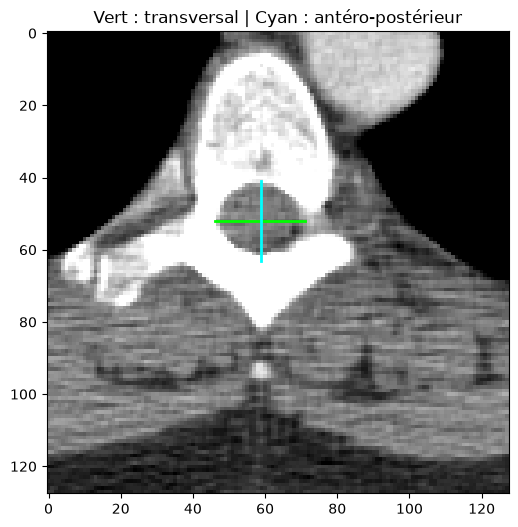

In [10]:
from scipy.ndimage import uniform_filter1d

def mesure_mi_hauteur(profil, centre, taille_pixel, recherche=30, max_mm=25):
    p = uniform_filter1d(profil.astype(np.float32), size=3)       # 1. lissage
    interieur = np.median(p[centre - 3:centre + 4])               # 2. valeur dans le canal
    bords = []
    for sens in (-1, +1):                                          # gauche puis droite
        zone = p[centre::sens][:recherche]                        # on s'éloigne du centre
        i_pic = int(np.argmax(zone))
        seuil = (interieur + zone[i_pic]) / 2                      # 3. mi-hauteur
        if zone[i_pic] - interieur < 50:                           # garde-fou : pas de vraie paroi
            return None, "pas de paroi nette d'un côté"
        i_bord = int(np.argmax(zone[:i_pic + 1] >= seuil))         # 1er point au-dessus du seuil
        bords.append(centre + sens * i_bord)
    g, d = bords
    largeur_mm = (d - g) * taille_pixel
    if largeur_mm > max_mm:
        return None, f"{largeur_mm:.1f} mm : invraisemblable"
    return (g, d, largeur_mm), "ok"

x_c, y_c = 59, 52    # centre du canal (milieu de 47 et 71)
res_t, msg_t = mesure_mi_hauteur(hu[y_c, :], x_c, dx)
res_ap, msg_ap = mesure_mi_hauteur(hu[:, x_c], y_c, dy)
print("Transversal       :", f"{res_t[2]:.1f} mm" if res_t else f"INVALIDE ({msg_t})")
print("Antéro-postérieur :", f"{res_ap[2]:.1f} mm" if res_ap else f"INVALIDE ({msg_ap})")

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img_mous, cmap="gray")
if res_t:  ax.plot([res_t[0], res_t[1]], [y_c, y_c], color="lime", lw=2)
if res_ap: ax.plot([x_c, x_c], [res_ap[0], res_ap[1]], color="cyan", lw=2)
ax.set_title("Vert : transversal | Cyan : antéro-postérieur")
plt.show()